In [1]:
import sys
sys.executable

'c:\\Users\\21074\\projects\\olist-analytics\\.venv\\Scripts\\python.exe'

In [2]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

set_style()

run_query("SELECT COUNT(*) AS n FROM dwd_orders")

,n
0,99441


In [3]:
run_query("DESCRIBE dwd_orders")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,customer_id,char(32),NO,,None,
2,customer_unique_id,char(32),NO,MUL,None,
3,customer_state,char(2),NO,,None,
4,order_status,varchar(20),NO,,None,
5,purchase_ts,datetime,NO,,None,
6,purchase_month,char(7),NO,MUL,None,
7,approved_ts,datetime,YES,,None,
8,delivered_carrier_ts,datetime,YES,,None,
9,delivered_customer_ts,datetime,YES,,None,


In [4]:
run_query("DESCRIBE dwd_customers")

,Field,Type,Null,Key,Default,Extra
0,customer_id,char(32),NO,PRI,None,
1,customer_unique_id,char(32),NO,MUL,None,
2,zip_code_prefix,char(5),NO,,None,
3,city,varchar(64),NO,,None,
4,state,char(2),NO,,None,
5,lat,double,YES,,None,
6,lng,double,YES,,None,


In [5]:
run_query("DESCRIBE dwd_order_reviews")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,review_id,char(32),NO,,None,
2,review_score,tinyint,NO,,None,
3,first_review_score,tinyint,NO,,None,
4,n_reviews,tinyint,NO,,None,
5,review_creation_date,date,NO,,None,
6,review_answer_ts,datetime,NO,,None,
7,review_comment_message,text,YES,,None,
8,has_comment,tinyint,NO,,None,
9,is_multi_review,tinyint,NO,,None,


In [6]:
run_query("DESCRIBE dwd_orders")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,customer_id,char(32),NO,,None,
2,customer_unique_id,char(32),NO,MUL,None,
3,customer_state,char(2),NO,,None,
4,order_status,varchar(20),NO,,None,
5,purchase_ts,datetime,NO,,None,
6,purchase_month,char(7),NO,MUL,None,
7,approved_ts,datetime,YES,,None,
8,delivered_carrier_ts,datetime,YES,,None,
9,delivered_customer_ts,datetime,YES,,None,


In [7]:
run_query("DESCRIBE dwd_order_items")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,order_item_id,smallint,NO,PRI,None,
2,product_id,char(32),NO,MUL,None,
3,seller_id,char(32),NO,MUL,None,
4,category_en,varchar(64),NO,,None,
5,shipping_limit_ts,datetime,NO,,None,
6,price,"decimal(10,2)",NO,,None,
7,freight_value,"decimal(10,2)",NO,,None,


In [8]:
run_query("DESCRIBE dwd_sellers")

,Field,Type,Null,Key,Default,Extra
0,seller_id,char(32),NO,PRI,None,
1,zip_code_prefix,char(5),NO,,None,
2,city,varchar(64),NO,,None,
3,state,char(2),NO,,None,
4,lat,double,YES,,None,
5,lng,double,YES,,None,


In [9]:
sql = """WITH valid_order AS(
	SELECT order_id, purchase_month
	FROM dwd_orders
	WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
),
gmv_per_order AS (
	SELECT valid_order.order_id, purchase_month, SUM(price) AS order_gmv
	FROM valid_order JOIN dwd_order_items USING (order_id)
	GROUP BY order_id, purchase_month
)
SELECT purchase_month, COUNT(*) AS orders, SUM(order_gmv) AS gmv_brl, SUM(SUM(order_gmv)) OVER(ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING) AS total_gmv
FROM gmv_per_order
GROUP BY purchase_month
ORDER BY purchase_month;"""

df = run_query(sql)
df

,purchase_month,orders,gmv_brl,total_gmv
0,2017-01,750,111798.36,13179777.95
1,2017-02,1653,234223.40,13179777.95
2,2017-03,2546,359198.85,13179777.95
3,2017-04,2303,340669.68,13179777.95
4,2017-05,3545,489159.25,13179777.95
5,2017-06,3135,421923.37,13179777.95
6,2017-07,3872,481604.52,13179777.95
7,2017-08,4193,554699.70,13179777.95
8,2017-09,4150,607399.67,13179777.95
9,2017-10,4478,648247.65,13179777.95


In [10]:
print(len(df), df["orders"].sum(), round(df["gmv_brl"].sum(), 2))

20 96203 13179777.95


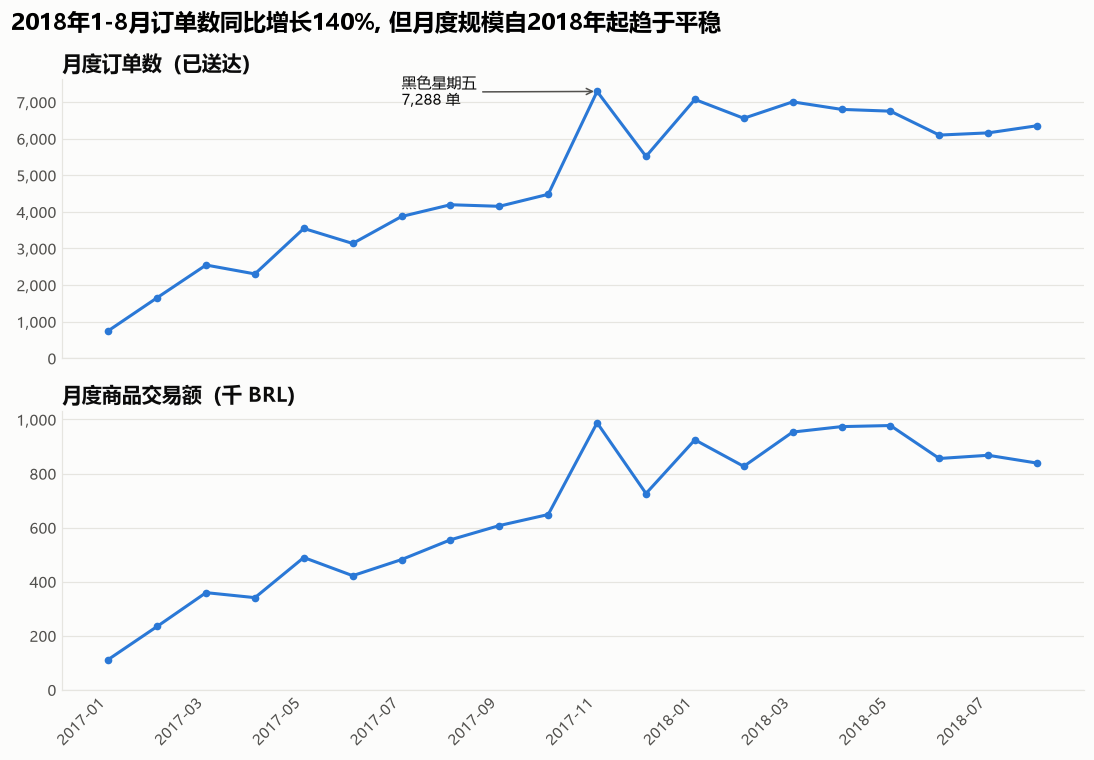

In [24]:
# 一张纸上建两个坐标系：2行1列，上下排列
# sharex=True 表示上下两张图共用横轴，月份只需在最下面显示一次
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# 上图：订单数（和第2步一样，只是把 ax 换成了 ax1）
ax1.plot(df["purchase_month"], df["orders"], color=COLORS["blue"], marker="o", markersize=4)
ax1.set_title("月度订单数（已送达）")
ax1.set_ylim(bottom=0)
# 在上图中标注 2017-11 的峰值
nov_idx = df.index[df["purchase_month"] == "2017-11"][0]       # 找到 2017-11 是第几行
nov_orders = df.loc[nov_idx, "orders"]
ax1.annotate(f"黑色星期五\n{nov_orders:,} 单",
             xy=(nov_idx, nov_orders),                          # 箭头指向这个点
             xytext=(nov_idx - 4, nov_orders * 0.95),           # 文字放在左边
             fontsize=10, color=COLORS["text"],
             arrowprops=dict(arrowstyle="->", color=COLORS["text_secondary"]))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# 下图：交易额，除以1000，单位变成"千 BRL"，数字更好读
ax2.plot(df["purchase_month"], df["gmv_brl"] / 1000, color=COLORS["blue"], marker="o", markersize=4)
ax2.set_title("月度商品交易额（千 BRL）")
ax2.set_ylim(bottom=0)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# 横轴标签只需要设置在下图
ax2.set_xticks(range(0, len(df), 2))
ax2.set_xticklabels(df["purchase_month"][::2], rotation=45, ha="right")

# 整张图的大标题：写结论
fig.suptitle("2018年1-8月订单数同比增长140%, 但月度规模自2018年起趋于平稳", x=0.01, ha="left", fontsize=15, fontweight="bold")

fig.tight_layout()   # 自动调整间距，防止标题和标签互相重叠

fig.savefig("../docs/figures/fig1_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

观察:
1. 整体趋势是呈增长趋势, 17年1月至18年8月 订单数大约增长了6-7倍.
2. 17年11月最突出, 可能与当地的消费文化习惯有关或者当地发生了一件影响销售额的事(我本人目前对巴西的商业文化等不太了解).
3. 18年的走势相对平稳, 17年的走势总体是持续上升的.

In [18]:
dif = df["orders"].iloc[-1] / df["orders"].iloc[0] 
dif

np.float64(8.468)

In [19]:
df["year"] = df["purchase_month"].str[:4]
df["mounth"] = df["purchase_month"].str[5:]
df[df["mounth"] <= "08"].groupby("year")["orders"].sum()

year
2017    21997
2018    52777
Name: orders, dtype: int64

In [20]:
#客单价
df["aov"] = df["gmv_brl"] / df["orders"]
df["aov"].describe()

count     20.000000
mean     138.086202
std        7.094059
min      124.381333
25%      132.228513
50%      139.169349
75%      143.597364
max      149.064480
Name: aov, dtype: float64

发现17年11月大幅上升, 考虑为“黑色星期五(17年11月24日)”商业文化导致, 如果该假设成立, 那么数据应立即呈现 11月的订单集中在24日前后 而非均匀分布全月. 下验证假设.

In [21]:
sql = """
  WITH valid_order AS (
    SELECT order_id, DATE(purchase_ts) AS purchase_date
    FROM dwd_orders
    WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0 AND YEAR(purchase_ts) = 2017 AND MONTH(purchase_ts) = 11
  )
  SELECT purchase_date, COUNT(*) AS orders
  FROM valid_order
  GROUP BY purchase_date
  ORDER BY purchase_date;
"""
df_nov = run_query(sql)
df_nov

,purchase_date,orders
0,2017-11-01,108
1,2017-11-02,117
2,2017-11-03,138
3,2017-11-04,106
4,2017-11-05,137
5,2017-11-06,182
6,2017-11-07,154
7,2017-11-08,169
8,2017-11-09,182
9,2017-11-10,159


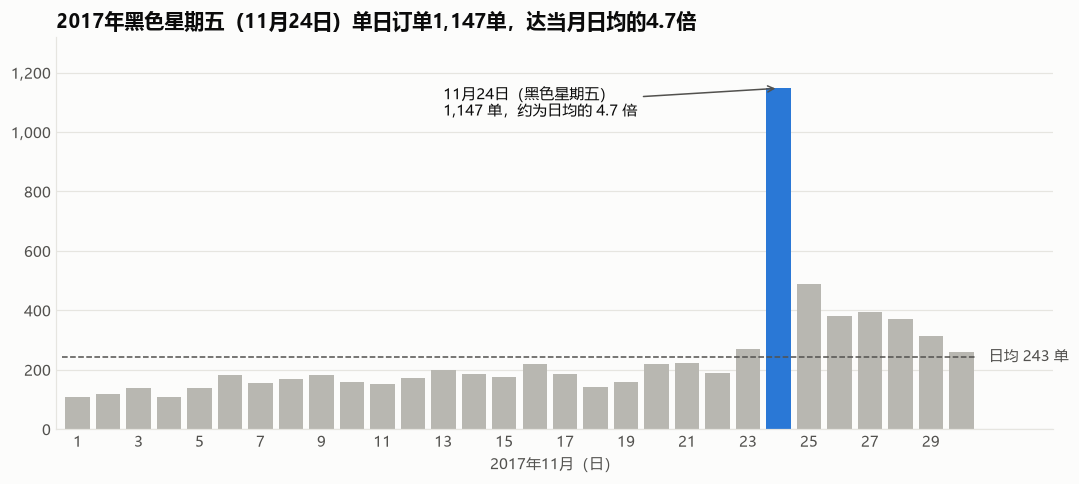

In [25]:
import pandas as pd

# ---------- 准备数据 ----------
dates = pd.to_datetime(df_nov["purchase_date"])     # 把日期转成 pandas 能识别的日期格式
peak_date = "2017-11-24"                            # 我们假设的高峰日（黑色星期五）
avg_orders = df_nov["orders"].mean()                # 11月日均订单数
peak_orders = df_nov.loc[dates == peak_date, "orders"].iloc[0]   # 取出24日那天的订单数

# 强调：24日用蓝色，其他日子用灰色
colors = [COLORS["blue"] if d == peak_date else COLORS["gray"]
          for d in dates.dt.strftime("%Y-%m-%d")]

# ---------- 画图 ----------
fig, ax = plt.subplots(figsize=(10, 4.5))

# 柱状图：横轴是几号（1–30），纵轴是订单数，每根柱子按 colors 上色
ax.bar(dates.dt.day, df_nov["orders"], color=colors, width=0.8)

# 参考线：画一条虚线表示日均水平，并在右端标注数值
ax.hlines(avg_orders, 0.5, 30.5, color=COLORS["text_secondary"], linewidth=1, linestyles="--")
ax.text(30.9, avg_orders, f"日均 {avg_orders:,.0f} 单", va="center",
        fontsize=10, color=COLORS["text_secondary"])

# 注释：用箭头指向高峰那根柱子，写上数字
ax.annotate(f"11月24日（黑色星期五）\n{peak_orders:,} 单，约为日均的 {peak_orders / avg_orders:.1f} 倍",
            xy=(24, peak_orders),                    # 箭头指向的位置
            xytext=(13, peak_orders * 0.92),         # 文字放置的位置
            fontsize=10, color=COLORS["text"],
            arrowprops=dict(arrowstyle="->", color=COLORS["text_secondary"]))

# ---------- 坐标轴 ----------
ax.set_xticks(range(1, 31, 2))                       # 横轴每隔一天显示一个标签
ax.set_xlabel("2017年11月（日）")
ax.set_ylim(0, peak_orders * 1.15)                   # 纵轴从0开始，顶部留一点空间给注释
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(0.3, 33)                                 # 右侧留出空间放"日均"标签

ax.set_title("2017年黑色星期五（11月24日）单日订单1,147单，达当月日均的4.7倍")
fig.tight_layout()

fig.savefig("../docs/figures/fig2_18November_trend.png", dpi=150, bbox_inches="tight")
plt.show()